# Constrained Optimization, Convexity, Lagrange Multipliers, and KKT

**AI Mathematics · 5. Optimization**

Explore feasible regions, convex functions, Lagrange multipliers, and the KKT conditions behind constrained optimization.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Recognize convex sets and functions.
- Form the Lagrangian for equality constraints.
- Interpret inequality constraints and KKT conditions.

In [1]:
import numpy as np

## 1. Convexity
A set is convex if the line segment between any two points in it lies in the set. A function is convex if its epigraph is convex; for a twice-differentiable function on a convex domain, a positive-semidefinite Hessian is a sufficient and necessary local curvature characterization. Every local minimum of a convex function is global.

In [2]:
import numpy as np

# Convex quadratic: Hessian is positive definite
H = np.array([[2.0, 0.0], [0.0, 4.0]])
print(np.linalg.eigvalsh(H))

# Indefinite Hessian indicates nonconvex curvature
H2 = np.array([[1.0, 0.0], [0.0, -1.0]])
print(np.linalg.eigvalsh(H2))

[2. 4.]
[-1.  1.]


## 2. Equality constraints and Lagrange multipliers
To optimize \(f(x)\) subject to \(g(x)=0\), form \(\mathcal{L}(x,\lambda)=f(x)+\lambda g(x)\). At a regular optimum, the gradient of the Lagrangian is zero alongside feasibility. Multipliers can be interpreted as sensitivity of the optimum value to constraint changes under appropriate conditions.

In [3]:
# Minimize x^2 + y^2 subject to x + y = 1.
# Symmetry gives x=y=0.5; solve the KKT stationarity equations numerically by linear algebra.
# grad f + lambda * grad g = 0, and x+y=1.
KKT = np.array([[2.0, 0.0, 1.0], [0.0, 2.0, 1.0], [1.0, 1.0, 0.0]])
rhs = np.array([0.0, 0.0, 1.0])
solution = np.linalg.solve(KKT, rhs)
print("x, y, lambda:", solution)

x, y, lambda: [ 0.5  0.5 -1. ]


## 3. Inequality constraints and KKT
For constraints \(g_i(x)\leq 0\), KKT includes primal feasibility, dual feasibility \(\lambda_i\geq 0\), stationarity, and complementary slackness \(\lambda_i g_i(x)=0\). KKT conditions require suitable regularity assumptions; for convex problems they give powerful global optimality conditions.

In [4]:
# Minimize (x-2)^2 subject to x <= 1.
# Express g(x)=x-1 <= 0. The optimum is at the boundary x=1.
x_star = 1.0
g = x_star - 1.0
grad_f = 2*(x_star-2)
# Stationarity: grad_f + lambda*1 = 0 => lambda=2
lambda_star = -grad_f
print("feasible g(x)<=0:", g <= 1e-12)
print("lambda >= 0:", lambda_star >= 0)
print("complementary slackness:", lambda_star*g)

feasible g(x)<=0: True
lambda >= 0: True
complementary slackness: 0.0


## 4. Quadratic programming and SVM connection
A quadratic program minimizes a quadratic objective under linear constraints. The soft-margin support vector machine is commonly formulated as a convex quadratic optimization problem with slack variables and margin constraints. Solver details are often handled by an optimization library, but the convex structure explains why global solutions can be found.

In [5]:
# Generic quadratic objective: 0.5*x^T Q*x + c^T*x
Q = np.array([[2.0, 0.0], [0.0, 4.0]])
c = np.array([-2.0, -8.0])
# Unconstrained minimizer solves Qx + c = 0.
x_star = np.linalg.solve(Q, -c)
print(x_star)
print("gradient at solution:", Q @ x_star + c)

[1. 2.]
gradient at solution: [0. 0.]


## 5. When constraints change the answer
The unconstrained optimum may be infeasible. In constrained learning, constraints can represent budgets, fairness requirements, nonnegative coefficients, or norm limits. Always distinguish the objective from the feasible set, and check that returned candidates satisfy the constraints.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: feasible regions and constrained optima

An optimization problem with constraints only allows solutions in a feasible set. The objective's unconstrained optimum may lie outside that region, so the constrained solution can land on a boundary. The shaded triangle below represents \(x\ge 0\), \(y\ge 0\), and \(x+y\le 2\).

16_constrained_and_convex_optimization.ipynb:cell14:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


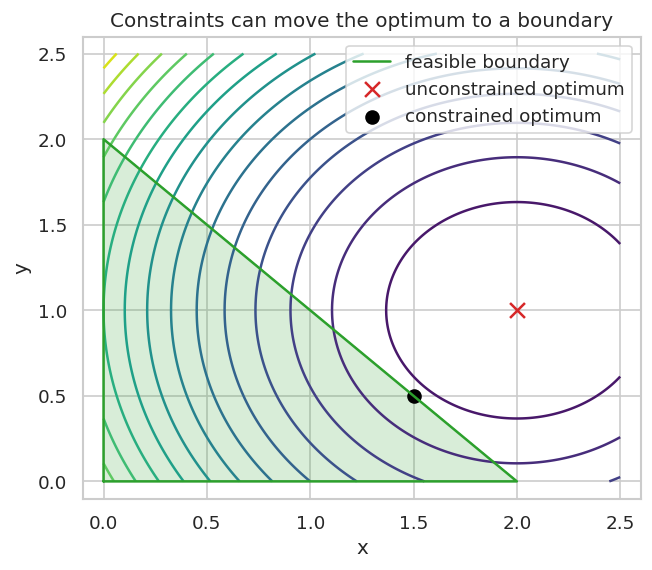

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_con_x = np.linspace(0, 2.5, 250)
viz_con_y = np.linspace(0, 2.5, 250)
viz_con_X, viz_con_Y = np.meshgrid(viz_con_x, viz_con_y)
viz_con_Z = (viz_con_X-2)**2 + (viz_con_Y-1)**2
viz_con_feasible = (viz_con_X >= 0) & (viz_con_Y >= 0) & (viz_con_X+viz_con_Y <= 2)
fig, ax = plt.subplots(figsize=(6, 5))
ax.contour(viz_con_X, viz_con_Y, viz_con_Z, levels=15, cmap="viridis")
ax.contourf(viz_con_X, viz_con_Y, viz_con_feasible.astype(float), levels=[0.5, 1.5], alpha=0.18, colors=["tab:green"])
ax.plot([0, 2, 0, 0], [0, 0, 2, 0], color="tab:green", label="feasible boundary")
ax.scatter([2], [1], marker="x", s=80, color="tab:red", label="unconstrained optimum")
ax.scatter([1.5], [0.5], s=60, color="black", label="constrained optimum")
ax.set_xlim(-0.1, 2.6); ax.set_ylim(-0.1, 2.6); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()
ax.set_title("Constraints can move the optimum to a boundary"); plt.show()

### Verify a candidate and compare objective values

A feasible point satisfies all constraints; an optimal point also minimizes the objective among feasible points. In practical problems, satisfying constraints numerically may require a tolerance rather than exact equality because floating-point calculations introduce small errors.

16_constrained_and_convex_optimization.ipynb:cell16:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,candidate,x,y,feasible,objective
0,A,1.5,0.5,True,0.50
1,B,1.8,0.5,False,0.29
2,C,0.5,1.0,True,2.25


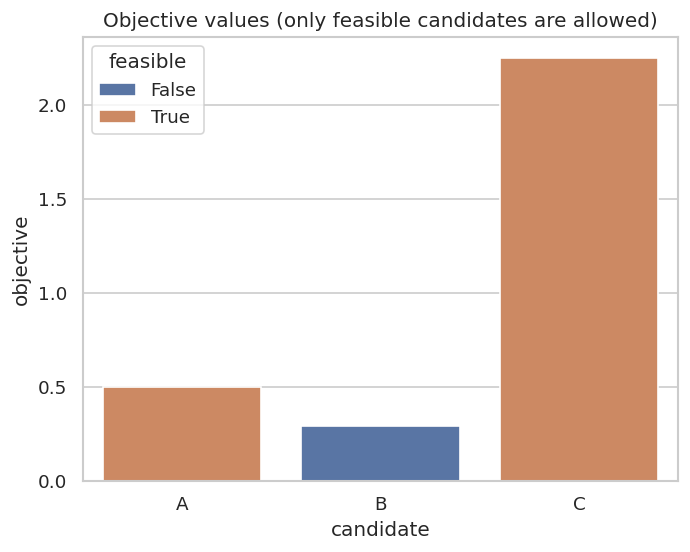

In [7]:
viz_con_candidates = pd.DataFrame({"candidate": ["A", "B", "C"], "x": [1.5, 1.8, 0.5], "y": [0.5, 0.5, 1.0]})
viz_con_candidates["feasible"] = (viz_con_candidates["x"] >= 0) & (viz_con_candidates["y"] >= 0) & (viz_con_candidates["x"]+viz_con_candidates["y"] <= 2+1e-10)
viz_con_candidates["objective"] = (viz_con_candidates["x"]-2)**2 + (viz_con_candidates["y"]-1)**2
display(viz_con_candidates)
sns.barplot(data=viz_con_candidates, x="candidate", y="objective", hue="feasible")
plt.title("Objective values (only feasible candidates are allowed)"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Minimize (x-3)^2 subject to x<=2.

In [8]:
x_star = min(3.0, 2.0)
print(x_star, "objective:", (x_star-3)**2)

2.0 objective: 1.0


### Exercise 2
Exercise 2: State the four common KKT components for inequality constraints.

In [9]:
# Primal feasibility, dual feasibility, stationarity, and complementary slackness.

## Key takeaways
- Convexity makes optimization more predictable because local minima are global minima.
- Lagrange multipliers combine objective gradients with constraint gradients.
- KKT conditions combine feasibility, stationarity, multiplier signs, and complementary slackness.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.